In [3]:
import networkx as nx
import pandas as pd
import os
df = pd.read_csv("training_set_metadata.csv", sep=";")
df.head()

,name,64-bit execution via heavens gate,64bits,PEB access,accept command line arguments,access the Windows event log,act as TCP client,allocate RW memory,allocate RWX memory,allocate memory,...,winzip,wise,worm,write and execute a file,write clipboard data,write file on Linux,write file on Windows,write pipe,xorcrypt,yoda
0,9fbf213113ba0a18dc2642f83b1201541428fd7951d6a8...,0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,1b35c9dbf3cd9ac60015aaa6cd451c898defa6dac1ff43...,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,1,0,0,0
2,bf8d307a136a936f7338c1f2eec773c4eb1c802cab77da...,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,1e51933903f0358c0b635f863368eb15a61cd3442bc5bf...,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,8a6503fe68d699f8a31531c157e9da931192cd7e3ec809...,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [271]:
'''import joblib

# Sauvegarder le modèle
joblib.dump(model, 'model_trained.pkl')

# Charger le modèle
model = joblib.load('model_trained.pkl')
'''


"import joblib\n\n# Sauvegarder le modèle\njoblib.dump(model, 'model_trained.pkl')\n\n# Charger le modèle\nmodel = joblib.load('model_trained.pkl')\n"

In [4]:

df = df.iloc[:2000,:]

In [7]:
import os
import re
import networkx as nx
import pandas as pd
from tqdm import tqdm
from collections import Counter
from concurrent.futures import ProcessPoolExecutor

directory = "folder_training_set"

# Compilation des regex pour optimiser les performances
EDGE_REGEX = re.compile(r'"(\d+)"\s*->\s*"(\d+)"')
NODE_REGEX = re.compile(r'"(\d+)"\s*\[label\s*=\s*"(.*?)"\]')
MNEMONIC_CLEANER = re.compile(r'[^a-zA-Z]')

def parse_cfg_file(cfg_path):
    """Lit le fichier de CFG et retourne une liste de lignes nettoyées."""
    try:
        with open(cfg_path, "r", encoding="utf-8", errors="ignore") as f:
            return f.read().splitlines()
    except Exception:
        return []

def extract_features(name):
    cfg_path = os.path.join(directory, f"{name}.json")
    if not os.path.exists(cfg_path):
        return 0, 0, 0, 0, 0, 0, pd.DataFrame()
    
    try:
        lines = parse_cfg_file(cfg_path)
        G = nx.DiGraph()
        assembly_instructions = []

        # Parsing rapide des lignes
        for line in lines:
            edge_match = EDGE_REGEX.search(line)
            if edge_match:
                src, dst = edge_match.groups()
                G.add_edge(src, dst)
                continue
            
            node_match = NODE_REGEX.search(line)
            if node_match:
                node_id, label = node_match.groups()
                parts = label.split(":", 2)
                instruction = parts[2].strip() if len(parts) >= 3 else parts[-1].strip()
                mnemonic = MNEMONIC_CLEANER.sub('', instruction.split()[0]) if instruction else ""
                if mnemonic:
                    assembly_instructions.append(mnemonic)
        
        # Calcul des métriques du graphe
        num_nodes = G.number_of_nodes()
        num_edges = G.number_of_edges()
        avg_degree = sum(dict(G.degree()).values()) / num_nodes if num_nodes > 0 else 0
        density = nx.density(G) if num_nodes > 1 else 0
        num_scc = nx.number_strongly_connected_components(G)
        avg_clustering = nx.average_clustering(G) if num_nodes > 0 else 0

        # Comptage des instructions assembleur
        word_counts = Counter(assembly_instructions)
        df_asm = pd.DataFrame([word_counts]).fillna(0)
        
        return num_nodes, num_edges, avg_degree, density, num_scc, avg_clustering, df_asm
    
    except Exception as e:
        print(f"Erreur sur {name}: {e}")
        return 0, 0, 0, 0, 0, 0, pd.DataFrame()

def process_chunk(names_chunk):
    return [extract_features(name) for name in names_chunk]

if __name__ == '__main__':
    df = pd.read_csv("training_set_metadata.csv", sep=";")
    df = df.iloc[:1000]
    names = df["name"].tolist()
    
    num_workers = os.cpu_count() or 4
    chunks = [names[i::num_workers] for i in range(num_workers)]
    
    with ProcessPoolExecutor(max_workers=num_workers) as executor:
        results_chunks = list(tqdm(executor.map(process_chunk, chunks),
                                   total=len(chunks),
                                   desc="Extraction des features"))
    
    # Fusion des résultats
    results = [item for sublist in results_chunks for item in sublist]
    df_features = pd.DataFrame([r[:6] for r in results],
                               columns=["num_nodes", "num_edges", "avg_degree", "density", "num_scc", "avg_clustering"])
    df_assembly_features = pd.concat([r[6] for r in results], axis=0).fillna(0)
    
    df.reset_index(drop=True, inplace=True)
    df_features.reset_index(drop=True, inplace=True)
    df_assembly_features.reset_index(drop=True, inplace=True)
    
    df_final = pd.concat([df, df_features, df_assembly_features], axis=1)
    df_final.to_csv("dataset_with_features.csv", index=False)
    print("✅ Extraction terminée !")


Process SpawnProcess-1:
Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.12/multiprocessing/process.py", line 314, in _bootstrap
    self.run()
  File "/opt/anaconda3/lib/python3.12/multiprocessing/process.py", line 108, in run
    self._target(*self._args, **self._kwargs)
  File "/opt/anaconda3/lib/python3.12/concurrent/futures/process.py", line 251, in _process_worker
    call_item = call_queue.get(block=True)
                ^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/opt/anaconda3/lib/python3.12/multiprocessing/queues.py", line 122, in get
    return _ForkingPickler.loads(res)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^
AttributeError: Can't get attribute 'process_chunk' on <module '__main__' (<class '_frozen_importlib.BuiltinImporter'>)>
Process SpawnProcess-2:
Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.12/multiprocessing/process.py", line 314, in _bootstrap
    self.run()
  File "/opt/anaconda3/lib/python3.12/multiprocessing/process.py", line 108

BrokenProcessPool: A child process terminated abruptly, the process pool is not usable anymore

In [1]:
df_features.shape, df_assembly_features.shape

NameError: name 'df_features' is not defined

In [ ]:
from sklearn.model_selection import train_test_split

# Séparer les features et labels
# Séparer les features et labels
X =df.iloc[:, 454:]

y = df.drop(columns=["name"] + list(X.columns))  # Mets ici la colonne correspondant aux 459 labels
X = X.loc[:, X.nunique() > 90]  # Supprimer les colonnes avec moins de 5 valeurs uniques
# Division en train (80%) et test (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Vérification des dimensions
print(f"Taille train : {X_train.shape}, Taille test : {X_test.shape}")


Taille train : (160, 26), Taille test : (40, 26)


In [179]:
df_features.to_csv("200_features.csv", index=False)
df_assembly_features.to_csv("200_assembly_features.csv", index=False)

In [180]:
df_features = pd.read_csv("200_features.csv")
df_assembly_features = pd.read_csv("200_assembly_features.csv")
df = df.reset_index(drop=True)
df_features = df_features.reset_index(drop=True)
df_assembly_features = df_assembly_features.reset_index(drop=True)
# Concatenate the DataFrames
df = pd.concat([df, df_features, df_assembly_features], axis=1)

In [43]:
df0 = pd.read_csv("test.csv")
df1 = pd.read_csv("test1.csv")
df = pd.concat([df0, df1], axis=0, ignore_index=True)


In [44]:
df0.shape, df1.shape, df.shape

((100, 1217), (100, 1719), (200, 1867))

In [45]:
df.sum()

name                                 9fbf213113ba0a18dc2642f83b1201541428fd7951d6a8...
64-bit execution via heavens gate                                                    2
64bits                                                                              48
PEB access                                                                          50
accept command line arguments                                                       36
                                                           ...                        
vpaddsb                                                                            1.0
pmaxub                                                                             1.0
lgs                                                                                1.0
fsincos                                                                            1.0
pmullw                                                                             1.0
Length: 1867, dtype: object

In [46]:
df.shape

(200, 1867)

In [127]:
import networkx as nx
import os
import numpy as np
from tqdm import tqdm
from concurrent.futures import ProcessPoolExecutor

directory = "folder_training_set"

def extract_features(name):
    cfg_path = os.path.join(directory, f"{name}.json")
    if not os.path.exists(cfg_path):
        return 0, 0, 0, 0

    try:
        G = nx.DiGraph()
        with open(cfg_path, "r", encoding="utf-8") as f:
            for line in f:
                line = line.strip()
                if "->" in line:  # Détecter les arêtes
                    src, dst = line.split("->")
                    src, dst = src.strip().strip('"'), dst.strip().strip('"')
                    G.add_edge(src, dst)
                elif "[" in line and "]" in line:  # Détecter les nœuds
                    node = line.split("[")[0].strip().strip('"')
                    G.add_node(node)

        deg_centrality = nx.degree_centrality(G)
        num_cycles = sum(1 for _ in nx.simple_cycles(G))
        centrality = np.mean(list(nx.betweenness_centrality(G).values()))
        sht_pth_len = nx.shortest_path_length(G)

    except Exception as e:
        print(f"Erreur sur {name}: {e}")
        return 0, 0, 0, 0  # Valeurs par défaut en cas d'erreur

    return  deg_centrality, num_cycles, centrality, sht_pth_len, 

# Parallélisation avec ProcessPoolExecutor

results = list(tqdm(map(extract_features, df["name"]), total=len(df), desc="Extraction des features"))

# Conversion en DataFrame
df_features_1 = pd.DataFrame(results, columns=[ "deg_centrality", "num_cycles", "centrality", "density"])
df = pd.concat([df, df_features_1], axis=1)


Extraction des features:   0%|          | 1/200 [00:08<27:09,  8.19s/it]


KeyboardInterrupt: 

In [1]:
df = pd.read_csv("1000_train_features.csv")
df.head()

<IPython.core.display.Javascript object>

,name,64-bit execution via heavens gate,64bits,PEB access,accept command line arguments,access the Windows event log,act as TCP client,allocate RW memory,allocate RWX memory,allocate memory,...,write file on Windows,write pipe,xorcrypt,yoda,Nombre de nœuds,Nombre d’arêtes,Degré moyen,Densité du graphe,num_strongly_connected_components,avg_clustering
0,9fbf213113ba0a18dc2642f83b1201541428fd7951d6a8...,0,1,0,0,0,0,0,0,0,...,0,0,0,0,2378,2674,2.248949,0.000473,1978,0.028037
1,1b35c9dbf3cd9ac60015aaa6cd451c898defa6dac1ff43...,0,0,0,0,0,0,0,0,0,...,1,0,0,0,6608,10308,3.119855,0.000236,4675,0.062766
2,bf8d307a136a936f7338c1f2eec773c4eb1c802cab77da...,0,0,0,0,0,0,0,0,0,...,0,0,0,0,385,385,2.000000,0.002604,385,0.000000
3,1e51933903f0358c0b635f863368eb15a61cd3442bc5bf...,0,0,0,0,0,0,0,0,0,...,0,0,0,0,865,974,2.252023,0.001303,737,0.005684
4,8a6503fe68d699f8a31531c157e9da931192cd7e3ec809...,0,0,0,0,0,0,0,0,0,...,0,0,0,0,258,278,2.155039,0.004193,208,0.013069


In [5]:
df.shape

(1000, 460)

In [6]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Columns: 460 entries, name to avg_clustering
dtypes: float64(3), int64(456), object(1)
memory usage: 3.5+ MB
None


In [2]:
from sklearn.model_selection import train_test_split

# Séparer les features et labels
# Séparer les features et labels
X =df.iloc[:, 454:]

y = df.drop(columns=["name"] + list(X.columns))  # Mets ici la colonne correspondant aux 459 labels
#X = X.loc[:, X.nunique() > 90]  # Supprimer les colonnes avec moins de 5 valeurs uniques
# Division en train (80%) et test (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Vérification des dimensions
print(f"Taille train : {X_train.shape}, Taille test : {X_test.shape}")


Taille train : (800, 6), Taille test : (200, 6)


In [3]:
y_test.columns

Index(['64-bit execution via heavens gate', '64bits', 'PEB access',
       'accept command line arguments', 'access the Windows event log',
       'act as TCP client', 'allocate RW memory', 'allocate RWX memory',
       'allocate memory', 'allocate or change RW memory',
       ...
       'winzip', 'wise', 'worm', 'write and execute a file',
       'write clipboard data', 'write file on Linux', 'write file on Windows',
       'write pipe', 'xorcrypt', 'yoda'],
      dtype='object', length=453)

In [9]:
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 6 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   Nombre de nœuds                    1000 non-null   int64  
 1   Nombre d’arêtes                    1000 non-null   int64  
 2   Degré moyen                        1000 non-null   float64
 3   Densité du graphe                  1000 non-null   float64
 4   num_strongly_connected_components  1000 non-null   int64  
 5   avg_clustering                     1000 non-null   float64
dtypes: float64(3), int64(3)
memory usage: 47.0 KB


In [4]:
from sklearn.multioutput import MultiOutputClassifier
from sklearn.ensemble import RandomForestClassifier
import random
# Création du modèle de classification multi-sortie
model = MultiOutputClassifier(RandomForestClassifier(n_estimators=1000, random_state=42))

# Entraînement du modèle
model.fit(X_train, y_train)  # y doit être un tableau 2D avec plusieurs cibles

# Prédiction
predictions = model.predict(X_test)


In [1]:
predictions.shape

NameError: name 'predictions' is not defined

In [ ]:
from sklearn.metrics import f1_score
f1_scores = f1_score(y_test, predictions, average="macro", zero_division=1)  # `average=None` pour obtenir F1 pour chaque cible

# Calcul du F1-score moyen
f1_macro = f1_score(y_test, predictions, average='macro', zero_division=1)  # Moyenne des F1-scores

# Affichage des résultats
print(f"F1-score pour chaque cible: {f1_scores}")
print(f"F1-score moyen (macro): {f1_macro}")

F1-score pour chaque cible: [0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.   

/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1509: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1509: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [226]:
# Créer un dataframe avec les labels et leurs scores F1
f1_df = pd.DataFrame({'label': y_test.columns, 'f1_score': f1_scores})

# Filtrer les labels avec un F1-score > 0
f1_df_filtered = f1_df[f1_df['f1_score'] > 0]

# Obtenir les labels correspondants
labels_with_f1_above_zero = f1_df_filtered['label'].tolist()

# Maintenant, tu peux filtrer le dataframe d'origine en fonction des labels

# Afficher les résultats
print(f1_df_filtered)

                                                 label  f1_score
1                                               64bits  0.714286
2                                           PEB access  0.200000
20                                            assembly  1.000000
27               calculate modulo 256 via x86 assembly  0.666667
29                                  capture screenshot  0.500000
46                          check for debugger via API  0.500000
59                                check if file exists  0.400000
72                                   checks-user-input  0.153846
83                         contain an embedded PE file  0.250000
88                                           copy file  0.500000
89                                             corrupt  1.000000
93   create a process with modified I/O handles and...  0.444444
94                                    create directory  0.470588
99                                 create or open file  0.588235
100                      

In [227]:
y = y[labels_with_f1_above_zero]

# Division en train (80%) et test (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"Taille train : {X_train.shape}, Taille test : {X_test.shape}")

Taille train : (160, 26), Taille test : (40, 26)


In [228]:
model.fit(X_train, y_train)
predictions = model.predict(X_test)

In [229]:
from sklearn.metrics import f1_score
f1_scores = f1_score(y_test, predictions, average=None)  # `average=None` pour obtenir F1 pour chaque cible

# Calcul du F1-score moyen
f1_macro = f1_score(y_test, predictions, average='macro')  # Moyenne des F1-scores

# Affichage des résultats
print(f"F1-score pour chaque cible: {f1_scores}")
print(f"F1-score moyen (macro): {f1_macro}")

F1-score pour chaque cible: [0.71428571 0.2        1.         0.66666667 0.5        0.5
 0.4        0.15384615 0.25       0.5        1.         0.44444444
 0.47058824 0.58823529 0.6        0.57142857 0.31578947 0.85714286
 0.42105263 0.41666667 0.5        0.64516129 0.66666667 0.59259259
 0.5        0.46153846 0.2        0.5        0.5        0.4
 0.6        0.36363636 0.28571429 0.57142857 0.52380952 0.44444444
 0.35294118 0.83870968 0.66666667 0.22222222 0.48       0.52631579
 0.25       0.2        0.25       0.44444444 0.48       0.38461538
 0.51612903]
F1-score moyen (macro): 0.48851394495673256


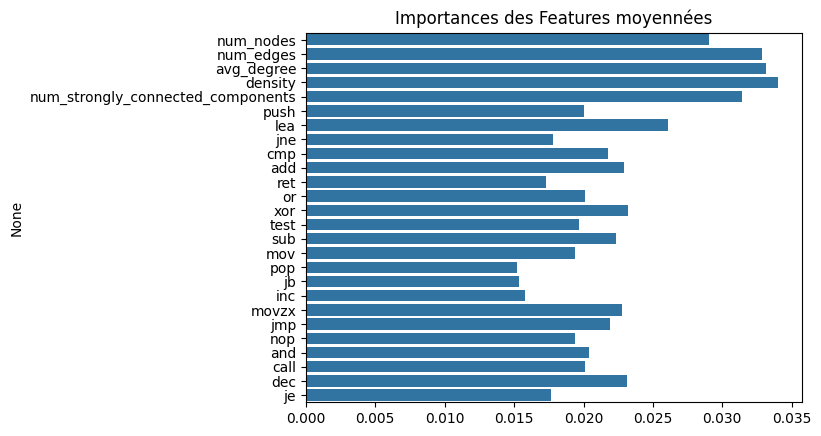

In [222]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Moyenne des importances des features sur tous les modèles internes
importances = np.mean([est.feature_importances_ for est in model.estimators_], axis=0)

# Affichage
sns.barplot(x=importances, y=X_train.columns)
plt.title("Importances des Features moyennées")
plt.show()


In [209]:
from sklearn.model_selection import cross_val_score
import numpy as np
scores = cross_val_score(model, X, y, cv=3, scoring="f1_macro", n_jobs=-1)
print("Variance du F1-score :", np.var(scores))


Variance du F1-score : 1.5301529899993986e-05


/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1509: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1509: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1509: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [75]:
df = pd.read_csv("test_asm.csv")
df

,0
0,scasd
1,iretd
2,push
3,retf
4,sahf
...,...
588173,neg
588174,movsx
588175,jmp
588176,rol


In [72]:
from sklearn.model_selection import train_test_split

# Séparer les features et labels
# Séparer les features et labels
X =df.iloc[:, 454:]

y = df.drop(columns=["name"] + list(X.columns))  # Mets ici la colonne correspondant aux 459 labels
X = X.loc[:, X.nunique() > 90]  # Supprimer les colonnes avec moins de 5 valeurs uniques
# Division en train (80%) et test (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Vérification des dimensions
print(f"Taille train : {X_train.shape}, Taille test : {X_test.shape}")


Taille train : (800, 40), Taille test : (200, 40)


In [ ]:
import fasttext
import numpy as np
from sklearn.metrics.pairwise import cosine_similarity

# Charger le modèle FastText
model = fasttext.load_model("Assembly_Model/fasttext_assembly_model.bin")

# Instructions à comparer
instr1 = "mov eax"
instr2 = "push epb"

# Récupérer les vecteurs d'embedding
vec1 = model.get_word_vector(instr1)
vec2 = model.get_word_vector(instr2)

# Calcul de la similarité cosinus
similarity_fasttext = cosine_similarity([vec1], [vec2])[0][0]
print(f"Similarité cosinus FastText : {similarity_fasttext}")


Similarité cosinus FastText : 0.12837599217891693


In [11]:
def append_file(source_file, destination_file):
    """
    Copie le contenu de `source_file` à la fin de `destination_file`.
    
    :param source_file: Chemin du fichier source (celui à copier).
    :param destination_file: Chemin du fichier de destination (celui à modifier).
    """
    try:
        # Ouvrir le fichier source en mode lecture
        with open(source_file, "r", encoding="utf-8") as src:
            # Lire tout le contenu du fichier source
            content = src.read()

        # Ouvrir le fichier de destination en mode ajout (append)
        with open(destination_file, "a", encoding="utf-8") as dest:
            # Écrire le contenu du fichier source à la fin du fichier de destination
            dest.write("\n")  # Ajouter une nouvelle ligne pour séparer les contenus
            dest.write(content)

        print(f"✅ Contenu de '{source_file}' copié à la fin de '{destination_file}'.")
    except Exception as e:
        print(f"❌ Erreur lors de la copie : {e}")

# Exemple d'utilisation
source = "/Users/nouroudine/Documents/Challenge_Sorbonne_2025/assembly_instructions_with_registers_2.txt"
destination = "/Users/nouroudine/Documents/Challenge_Sorbonne_2025/assembly_instructions_with_registers_1.txt"
append_file(source, destination)

✅ Contenu de '/Users/nouroudine/Documents/Challenge_Sorbonne_2025/assembly_instructions_with_registers_2.txt' copié à la fin de '/Users/nouroudine/Documents/Challenge_Sorbonne_2025/assembly_instructions_with_registers_1.txt'.


In [ ]:
from gensim.models import Word2Vec
from sklearn.decomposition import PCA
import numpy as np

def tokenization(label, n_components=10):
    # Nettoyer les labels indésirables ou malformés
    def clean_label(label):
        # Par exemple, ignorer certains labels malformés comme "dead0def"
        blacklist = ["dead0def", "UNDEF"]  # Liste des labels à ignorer
        for bad_label in blacklist:
            if bad_label in label:
                return ""  # Si le label est indésirable, le retourner comme vide
        return label

    # Séparation du label en différentes parties
    label = label.split(":")
    
    # Extraire et nettoyer l'assembly
    if len(label) > 3:
        assembly_tokens = label[-2].strip('"').strip() + " " + label[-1].strip('"').strip()
    elif len(label) == 3:
        assembly_tokens = label[-1].strip('"').strip()
    else:
        assembly_tokens = ""

    # Nettoyer le label d'assembly
    assembly_tokens = clean_label(assembly_tokens)
    
    # Si après nettoyage, l'assembly est vide, on retourne une liste vide
    if not assembly_tokens:
        return []

    # Tokenisation de l'assembly en mots
    assembly_tokens = assembly_tokens.split()  # Découpe la chaîne en mots
    
    # Entraîner le modèle Word2Vec avec les instructions tokenisées
    model = Word2Vec([assembly_tokens], vector_size=10, window=5, min_count=1, workers=4)
    
    # Exemple pour obtenir le vecteur d'un mot
    vectors = [model.wv[word] for word in assembly_tokens]

    # Appliquer PCA pour réduire la dimensionnalité des vecteurs
    if len(vectors) > 1:  # Si plusieurs vecteurs sont générés
        # Convertir les vecteurs en un tableau NumPy
        vectors_array = np.array(vectors)
        
        # Appliquer PCA pour réduire la dimensionnalité
        pca = PCA(n_components=n_components)
        reduced_vectors = pca.fit_transform(vectors_array)
        
        # Retourner la moyenne des vecteurs réduits (par exemple, vous pouvez choisir d'autres méthodes de réduction)
        return reduced_vectors.mean(axis=0)
    else:
        # Si un seul vecteur, on peut le retourner tel quel
        return vectors[0]

# Exemple d'utilisation
label = "[label = 140001052 : CALL : mov rdx, qword ptr [rip + 0x3487]]"
reduced_vector = tokenization(label, n_components=6)
print(reduced_vector)


In [32]:
from transformers import AutoModel, AutoTokenizer
import torch

# Charger le modèle CodeBERT et son tokenizer
model_name = "microsoft/codebert-base"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModel.from_pretrained(model_name)

import torch.nn.functional as F

code1 = "mov eax, 1"
code2 = "ret"

# Tokenisation
tokens1 = tokenizer(code1, return_tensors="pt", padding=True, truncation=True)
tokens2 = tokenizer(code2, return_tensors="pt", padding=True, truncation=True)

# Passage dans CodeBERT
with torch.no_grad():
    emb1 = model(**tokens1).last_hidden_state.mean(dim=1)
    emb2 = model(**tokens2).last_hidden_state.mean(dim=1)

# Calcul de la similarité cosinus
similarity = F.cosine_similarity(emb1, emb2)
print("Similarité entre les codes BERT:", similarity.item())


Similarité entre les codes BERT: 0.8655416965484619


In [33]:
import fasttext
import numpy as np
from sklearn.metrics.pairwise import cosine_similarity

# Charger le modèle FastText
model = fasttext.load_model("/Users/nouroudine/Documents/Challenge_Sorbonne_2025/Assembly_Model/Assembly_Model/fasttext_assembly_model.bin")

# Instructions à comparer

# Récupérer les vecteurs d'embedding
vec1 = model.get_word_vector(code1)
vec2 = model.get_word_vector(code2)

# Calcul de la similarité cosinus
similarity_fasttext = cosine_similarity([vec1], [vec2])[0][0]
print(f"Similarité cosinus FastText : {similarity_fasttext}")


Similarité cosinus FastText : 0.6274448037147522


In [ ]:
import fasttext
import os

path = "/Users/nouroudine/Documents/Challenge_Sorbonne_2025/assembly_instructions_with_registers_1.txt"
# Entraînement de FastText sur le texte des instructions
model = fasttext.train_unsupervised(path, model="skipgram", dim=20, minCount=1)

# Créer le répertoire si nécessaire
os.makedirs("./Assembly_Model", exist_ok=True)

# Sauvegarde du modèle
model.save_model("./fasttext_model.bin")

# Afficher l'embedding d'une instruction
print("Embedding pour 'mov eax' :", model.get_word_vector("mov eax"))

Read 432M words
Number of words:  29570
Number of labels: 0
Progress: 100.0% words/sec/thread: 10885762 lr:  0.000000 avg.loss:  1.283746 ETA:   0h 0m 0s


Embedding pour 'mov eax' : [ 0.2528274   0.20156567 -0.06128849  0.08985585  0.11030738  0.1664416
  0.44162336  0.16116917  0.5072388   0.5802413  -0.5693529   0.1981337
  0.23270954  1.1390011  -0.6468263  -0.4293247  -0.16158007  0.83217114
  0.13907635 -0.6464081 ]
[-0.00088143  0.01260793 -0.01610004  0.00905123  0.02399617  0.01081117
  0.05140851  0.02686486  0.05150174  0.03839652 -0.04667773  0.02423013
  0.0365386   0.08930359 -0.06554576 -0.04667567 -0.00551911  0.07561935
  0.00921223 -0.0295196 ]
